# 2. Predicting which bookings will be lost late (weeks 5-7)
We build the model step by step, and on the way fall into (and climb out of) the two classic traps: **leakage** and **random splits**.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hotel_ob import config, data, model, nights, policy
from hotel_ob.features import make_X
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
df = pd.read_parquet(config.PROCESSED_DIR / 'bookings.parquet')
train, test = data.time_split(df)
print(f'train: {train.sum():,} bookings before {config.TEST_START}, test: {test.sum():,} from then on')

train: 78,589 bookings before 2017-01-01, test: 40,619 from then on


## Trap 1: leaky columns
First predict *any* cancellation, once with only booking-time columns and once with four extra columns that the hotel only knows later.

In [3]:
_, auc_clean, _ = model.fit_eval(df, 'is_canceled', train, test)
_, auc_leak, _ = model.fit_eval(df, 'is_canceled', train, test, cat=config.CAT_FEATURES + config.LEAKY_FEATURES)
print(f'honest AUC {auc_clean:.3f}   with leaky columns {auc_leak:.3f}')

honest AUC 0.805   with leaky columns 0.865


In [4]:
park = df[df.required_car_parking_spaces > 0]
print(f'{len(park):,} bookings asked for parking; cancelled: {park.is_canceled.sum()}, no-shows: {(park.reservation_status == "No-Show").sum()}')

7,409 bookings asked for parking; cancelled: 0, no-shows: 0


Not one booking with a parking space was cancelled. That only makes sense if parking is recorded **on arrival**. Using it to predict cancellations is accidental cheating: the 0.06 jump in AUC is fake.

## Trap 2: a random split
Mixing 2015, 2016 and 2017 in both training and test lets the model learn from the future.

In [5]:
rng = np.random.default_rng(0)
rand = pd.Series(rng.random(len(df)) < 0.75, index=df.index)
_, auc_random, _ = model.fit_eval(df, 'is_canceled', rand, ~rand)
print(f'time split {auc_clean:.3f}   random split {auc_random:.3f}')

time split 0.805   random split 0.830


## The real target: lost late
Only bookings still active 7 days out; train on 2015-16, test on 2017.

In [6]:
tr, te = train & df.active, test & df.active
lr, auc_lr, p_lr = model.fit_eval(df, 'late', tr, te, 'logit')
gb, auc_gb, p_gb = model.fit_eval(df, 'late', tr, te, 'gb')
print(f'logistic AUC {auc_lr:.3f}   gradient boosting AUC {auc_gb:.3f}')
print(f'average prediction for 2017: {p_lr.mean():.1%}   what really happened: {df.loc[te, "late"].mean():.1%}')

logistic AUC 0.652   gradient boosting AUC 0.690
average prediction for 2017: 8.8%   what really happened: 6.0%


Predicting *late* losses is much harder than predicting any cancellation. And the model expects far more late losses than 2017 delivered. A calibration plot shows it bin by bin:

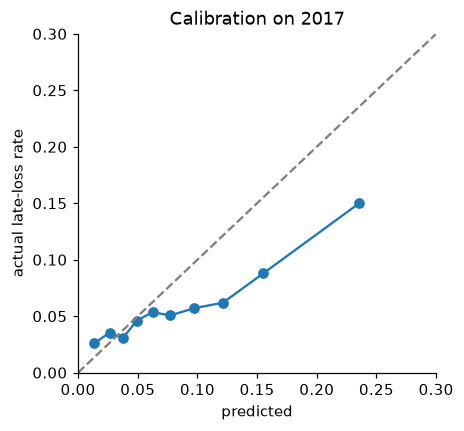

,bin,predicted,actual,n
0,0,0.014,0.026,2648
1,1,0.027,0.036,2647
2,2,0.037,0.031,2647
3,3,0.049,0.046,2647
4,4,0.062,0.054,2647
5,5,0.077,0.051,2647
6,6,0.097,0.057,2647
7,7,0.121,0.062,2647
8,8,0.155,0.088,2647
9,9,0.235,0.150,2648


In [7]:
cal = model.calibration_table(df.loc[te, 'late'], p_lr)
ax = cal.plot(x='predicted', y='actual', marker='o', figsize=(4.2, 4), legend=False, title='Calibration on 2017')
ax.plot([0, .3], [0, .3], ls='--', color='grey'); ax.set(xlim=(0, .3), ylim=(0, .3), ylabel='actual late-loss rate')
plt.show()
cal

## What drives the risk?
Each coefficient multiplies the odds of being lost late. Numbers are scaled, so compare signs and sizes, not units.

In [8]:
model.top_coefficients(lr, 10)

,feature,coef,odds_multiplier
0,deposit_type_Non Refund,2.058,7.834
1,deposit_type_No Deposit,-1.440,0.237
2,meal_FB,1.060,2.887
3,deposit_type_Refundable,-1.050,0.350
4,market_segment_Corporate,-0.831,0.436
5,customer_type_Group,-0.736,0.479
6,hotel_Resort Hotel,-0.666,0.514
7,distribution_channel_GDS,-0.622,0.537
8,meal_HB,-0.542,0.582
9,distribution_channel_Corporate,0.538,1.713


### Your turn
1. Train the logistic model with `LATE_WINDOW_DAYS = 3` instead of 7 (use `data.add_labels(df, window=3)`). Does AUC go up or down? Why?
2. Gradient boosting has a higher AUC. Would you use it in the overbooking rule? Hint: is AUC what the hotel cares about?
3. Remove `deposit_type` from the inputs. How much does AUC fall?